# PLN Projeto 2 — Extração de grafo de conhecimento clínico com N-grams e ML

**Pipeline**

1. Pré-processamento e gazetteer (Parte 1) com *matcher* de frases por maior casamento.
2. Análise de N-grams (frequência, PMI/NPMI) para descobrir entidades compostas candidatas.
3. NER como etiquetagem de sequências (CRF) com **supervisão fraca**: rótulos gerados pelo gazetteer.
4. Experimento de generalização: parte do léxico é escondida no treino; mede-se se o CRF recupera termos nunca vistos.
5. Classificação de relações entre pares de entidades (TF-IDF de N-grams + LogReg / ComplementNB / LinearSVC), também com supervisão fraca.
6. Descoberta de padrões de relação (n-grams discriminativos) e de gatilhos novos.
7. Negação de entidades ("no fever"): gatilhos estilo NegEx como rótulo fraco + classificador de n-grams.
8. Construção do grafo (regras × ML), métricas estruturais e visualização.

Dependências: `pip install scikit-learn sklearn-crfsuite networkx matplotlib pandas pyarrow`

In [1]:
import os, re, random, math, json
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED); np.random.seed(SEED)

CASES_PATH = "../../data/external/cases.csv"      # amostra pequena da Parte 1 (fallback)
META_PATH  = "../../data/external/metadata.csv"   # opcional
RAW_CASES  = "../../data/raw/cases.parquet"       # MultiCaRe v2.1 completo (Zenodo 14994046)
RAW_META   = "../../data/raw/metadata.parquet"
OUT_DIR    = "../../data/processed"
os.makedirs(OUT_DIR, exist_ok=True)

MAX_CASES      = 1500   # None = usa todos (CRF e grafos ficam lentos)
TEST_SIZE      = 0.2    # divisão por artigo (evita vazamento entre casos do mesmo artigo)
NEG_KEEP       = 0.3    # fração de sentenças sem entidade mantidas no treino do CRF
HIDE_FRAC      = 0.25   # fração do léxico escondida no experimento de generalização
HIDE_MIN_COUNT = 3      # só esconde termos com >= N ocorrências no treino
MAX_BETWEEN    = 10     # máx. de tokens entre duas entidades para formar um par de relação

## 1. Dados

In [2]:
if os.path.exists(RAW_CASES):
    # MultiCaRe v2.1: uma linha por artigo, com a lista de casos aninhada em 'cases'
    raw = pd.read_parquet(RAW_CASES).explode('cases').dropna(subset=['cases'])
    df = pd.json_normalize(raw['cases'].tolist())
    df.insert(0, 'article_id', raw['article_id'].values)
    meta_raw = pd.read_parquet(RAW_META)
    meta = pd.json_normalize(meta_raw['article_metadata'].tolist())
    meta.insert(0, 'article_id', meta_raw['article_id'].values)
    print(f"MultiCaRe completo: {len(df)} casos de {df.article_id.nunique()} artigos")
else:
    df = pd.read_csv(CASES_PATH)
    meta = pd.read_csv(META_PATH) if os.path.exists(META_PATH) else None
df = df.dropna(subset=['case_text']).drop_duplicates('case_id')
if meta is not None:
    df = df.merge(meta, on='article_id', how='left', suffixes=('', '_meta'))
if MAX_CASES and len(df) > MAX_CASES:
    df = df.sample(MAX_CASES, random_state=SEED)
df = df.reset_index(drop=True)

from sklearn.model_selection import GroupShuffleSplit
tr_idx, te_idx = next(GroupShuffleSplit(1, test_size=TEST_SIZE, random_state=SEED).split(df, groups=df['article_id']))
df_train, df_test = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
print(f"{len(df)} casos | treino: {len(df_train)} | teste: {len(df_test)}")
os.makedirs('../../data/interim', exist_ok=True)
df[['article_id', 'case_id', 'age', 'gender', 'case_text']].to_csv('../../data/interim/cases_sample.csv', index=False)  # amostra usada, para reprodutibilidade

MultiCaRe completo: 93816 casos de 72581 artigos


1500 casos | treino: 1197 | teste: 303


## 2. Pré-processamento e matcher de entidades

Correções em relação à Parte 1:

- **Matcher por frase**: a Parte 1 indexava *cada token* de um termo composto, então `acute`, `blood` ou `count` disparavam entidades isoladas e o último termo lido sobrescrevia os anteriores. Agora o casamento é por sequência de *stems*, com maior casamento à esquerda.
- **Tokenização** preserva hifens e alfanuméricos (`x-ray`, `c-reactive`, `hba1c`, `pd-l1`, `fev1`), que antes eram quebrados.
- **Resultados de exames** são extraídos por regex sobre o texto (unidade `U/L` era quebrada pelo tokenizador).
- IDs de nós determinísticos e processamento em lote (antes só `df.iloc[6]`).

In [3]:
TOKEN_RE = re.compile(r"""
    \d+(?:\.\d+)?
    |[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ0-9]*(?:[-'][A-Za-zÀ-ÿ0-9]+)*
    |[.,;:!?()%/\[\]=<>+-]
""", re.VERBOSE)

def tokenize(sent):
    return [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(sent)]

STEM_RE = re.compile(r'(?<!s)s$')
def stem(tok):
    return STEM_RE.sub('', tok.lower())

def split_sentences(text):
    return [s for s in re.split(r'(?<=[.!?])\s+(?=[A-Z0-9])', text.strip()) if s]

In [4]:
def build_gazetteers():
    return {
        'Diagnosis': ['diabetes mellitus', 'hypertension', 'acute pancreatitis', 'chronic pancreatitis', 'pancreatic pseudocyst', 'pseudocyst', 'solid mass', 'type 2 diabetes', 'tumor', 'cancer',
            'acute respiratory distress syndrome', 'sepsis', 'septic shock', 'pneumonia', 'pulmonary embolism', 'acute heart failure', 'congestive heart failure', 'myocardial infarction',
            'ischemic stroke', 'hemorrhagic stroke', 'acute kidney injury', 'chronic kidney disease', 'renal failure', 'acute liver failure', 'cirrhosis', 'hepatitis',
            'cholangitis', 'biliary obstruction', 'appendicitis', 'peritonitis', 'gastrointestinal bleeding', 'intestinal obstruction', 'peptic ulcer disease',
            'deep vein thrombosis', 'venous thromboembolism', 'anemia', 'thrombocytopenia', 'leukemia', 'lymphoma', 'hemolytic anemia', 'fatty liver disease',
            'metastatic disease', 'meningitis', 'encephalitis', 'pyelonephritis', 'urinary tract infection', 'bronchitis', 'asthma', 'pneumonitis', 'respiratory failure',
            'arrhythmia', 'atrial fibrillation', 'valvular disease', 'endocarditis', 'pericarditis', 'liver abscess', 'splenomegaly'
        ],
        'Symptom': ['epigastric pain', 'nausea', 'fever', 'epigastric tenderness', 'fat stranding', 'pain', 'headache', 'cough',
            'abdominal pain', 'vomiting', 'diarrhea', 'constipation', 'bloody stools', 'hematochezia', 'melena', 'shortness of breath', 'dyspnea', 'wheezing',
            'chest pain', 'palpitations', 'dizziness', 'syncope', 'fatigue', 'weakness', 'malaise', 'loss of appetite', 'anorexia', 'weight loss', 'weight gain',
            'swelling', 'edema', 'leg swelling', 'lower extremity edema', 'jaundice', 'dark urine', 'itching', 'pruritus', 'confusion', 'delirium', 'sleep disturbance',
            'insomnia', 'restlessness', 'anxiety', 'depression', 'tremor', 'muscle weakness', 'myalgia', 'arthralgia', 'back pain', 'joint pain', 'neck pain',
            'sore throat', 'hoarseness', 'hemoptysis', 'cyanosis', 'hematuria', 'dysuria', 'polyuria', 'oliguria', 'urinary retention', 'flank pain', 'cold intolerance',
            'heat intolerance', 'blurred vision', 'visual disturbance', 'vertigo', 'paresthesia', 'numbness', 'tingling', 'bruising', 'easy bruising', 'bleeding', 'nosebleed',
            'productive cough', 'nonproductive cough', 'dysphagia', 'odynophagia', 'hiccups', 'tachycardia', 'hypotension', 'hypertension symptoms', 'chills', 'rigors', 'sweating',
            'night sweats', 'burning sensation', 'pressure sensation', 'abdominal distension', 'bloating', 'gastroesophageal reflux', 'heartburn', 'dyspepsia', 'gastrointestinal pain', 'thirst',
            'polyuria', 'excessive thirst', 'hyperglycemia symptoms', 'hypoglycemia symptoms', 'fainting'
        ],
        'Exam': [
          'computed tomography', 'ct', 'thoracic ct', 'endoscopic ultrasound', 'eus', 'ultrasound', 'laboratory tests', 'mri', 'x-ray', 'echocardiogram', 'echocardiography', 'ecg', 'flow cytometry',
          'hemoglobin', 'hematocrit', 'white blood cell count', 'total leukocyte count', 'leucocytosis', 'lymphocyte count', 'platelet count', 'platelet counts', 'mean corpuscular volume', 
          'reticulocyte count', 'haptoglobin', 'adamts13 activity', 'c-reactive protein', 'crp', 'erythrocyte sedimentation rate', 'esr', 'creatinine', 'serum creatinine', 'albumin', 'total protein',
          'ferritin', 'lactate dehydrogenase', 'ldh', 'complement c3', 'complement c4', 'c3', 'c4', 'troponin', 'troponin i', 'ck-mb', 'creatine kinase', 'myoglobin', 'ejection fraction', 'lvef', 
          'mean gradient', 'nt-probnp', 'heart rate', 'blood pressure', 'mean arterial blood pressure', 'glycosylated hemoglobin', 'hemoglobin a1c', 'hba1c', 'blood sugar', 'immunoglobulin m', 
          'immunoglobulin g', 'igm', 'igg', 'igg levels', 'forced vital capacity', 'fvc', 'forced expiratory volume', 'fev1', 'diffusing capacity', 'dlco', 'oxygen saturation', 'respiratory rate', 
          'carcinoembryonic antigen', 'cea', 'pd-l1 tps score','hydroxychloroquine level', 'gtt',
      ],
        'Treatment': [
            'intravenous fluids', 'oral rehydration', 'analgesia', 'analgesics', 'pain control',
            'antibiotics', 'antiviral therapy', 'antifungal therapy', 'antiparasitic therapy',
            'anticoagulation', 'antiplatelet therapy', 'heparin', 'warfarin', 'enoxaparin',
            'insulin', 'metformin', 'glucose control', 'blood pressure control', 'antihypertensive therapy',
            'fluid resuscitation', 'electrolyte replacement', 'oxygen therapy', 'ventilation support',
            'corticosteroids', 'prednisone', 'hydrocortisone', 'dexamethasone', 'steroid therapy',
            'immunosuppressive therapy', 'plasma exchange', 'plasmapheresis', 'intravenous immunoglobulin', 'ivig',
            'chemotherapy', 'radiotherapy', 'targeted therapy', 'immunotherapy', 'hormonal therapy',
            'surgery', 'laparotomy', 'laparoscopy', 'resection', 'drainage', 'debridement',
            'endoscopic drainage', 'cystgastrostomy', 'gastrojejunostomy', 'stent placement', 'biliary drainage',
            'dialysis', 'renal replacement therapy', 'liver transplant', 'kidney transplant', 'transplantation',
            'blood transfusion', 'platelet transfusion', 'erythrocyte transfusion',
            'physical therapy', 'rehabilitation', 'respiratory physiotherapy', 'occupational therapy',
            'bronchodilator therapy', 'inhaled beta agonist', 'nebulized therapy', 'smoking cessation',
            'prophylactic antibiotics', 'empiric therapy', 'supportive care', 'palliative care',
            'nutritional support', 'enteral nutrition', 'parenteral nutrition', 'oral nutrition',
            'thrombolysis', 'vasopressor support', 'inotropic support', 'antiemetics', 'anti-inflammatory therapy',
            'antihistamines', 'acid suppression', 'proton pump inhibitor', 'ppi', 'antacids',
            'beta-blocker therapy', 'statin therapy', 'aspirin', 'ibuprofen', 'acetaminophen', 'paracetamol',
            'antidepressant therapy', 'antiepileptic therapy', 'antiarrhythmic therapy', 'diuretic therapy',
            'vaccination', 'immunization', 'monitoring', 'observation', 'watchful waiting', 'conservative management'
        ]
    }

In [5]:
ENT_TYPES = ['Diagnosis', 'Symptom', 'Exam', 'Treatment']
COND = {'Diagnosis', 'Symptom'}

def build_phrase_index(gaz):
    index, max_len = {}, 1
    for etype, kws in gaz.items():
        for kw in kws:
            key = tuple(stem(t[0]) for t in tokenize(kw))
            if key and key not in index:
                index[key] = (etype, kw)
                max_len = max(max_len, len(key))
    return index, max_len

def match_entities(tokens, index, max_len):
    """Maior casamento à esquerda. Retorna [(início, fim, tipo, termo_canônico)]."""
    stems = [stem(t[0]) for t in tokens]
    i, spans = 0, []
    while i < len(tokens):
        for n in range(min(max_len, len(tokens) - i), 0, -1):
            hit = index.get(tuple(stems[i:i + n]))
            if hit:
                spans.append((i, i + n, hit[0], hit[1]))
                i += n
                break
        else:
            i += 1
    return spans

def spans_to_bio(n, spans):
    tags = ['O'] * n
    for s, e, t, *_ in spans:
        tags[s] = f'B-{t}'
        for k in range(s + 1, e):
            tags[k] = f'I-{t}'
    return tags

def bio_to_spans(tags):
    spans, start, typ = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O' or tag.startswith('B-') or tag[2:] != typ:
            if typ is not None:
                spans.append((start, i, typ))
            start, typ = (i, tag[2:]) if tag != 'O' else (None, None)
    return spans

### Corpus em nível de sentença

- `gold`: entidades pelo gazetteer **completo** (usado como referência *silver*).
- `rules`: baseline da Parte 1 usando o gazetteer **reduzido** (sem os termos escondidos).
- O CRF é treinado com os rótulos do gazetteer reduzido e avaliado contra `gold`. Isso mede se ele recupera termos que as regras não conhecem.

In [6]:
def make_sentences(dfc):
    out = []
    for r in dfc.itertuples():
        for sid, sent in enumerate(split_sentences(r.case_text)):
            toks = tokenize(sent)
            if toks:
                out.append({'case_id': r.case_id, 'article_id': r.article_id, 'sid': sid, 'text': sent, 'tokens': toks})
    return out

sents_train, sents_test = make_sentences(df_train), make_sentences(df_test)

GAZ = build_gazetteers()
FULL_INDEX, FULL_MAXLEN = build_phrase_index(GAZ)
for s in sents_train + sents_test:
    s['gold'] = match_entities(s['tokens'], FULL_INDEX, FULL_MAXLEN)

# Léxico escondido (experimento de generalização)
kw_counts = Counter(sp[3] for s in sents_train for sp in s['gold'])
eligible = sorted(k for k, c in kw_counts.items() if c >= HIDE_MIN_COUNT)
HIDDEN = set(random.Random(SEED).sample(eligible, int(HIDE_FRAC * len(eligible))))
GAZ_RED = {t: [k for k in kws if k not in HIDDEN] for t, kws in GAZ.items()}
RED_INDEX, RED_MAXLEN = build_phrase_index(GAZ_RED)

for s in sents_train + sents_test:
    s['rules'] = match_entities(s['tokens'], RED_INDEX, RED_MAXLEN)

print(f"sentenças treino/teste: {len(sents_train)}/{len(sents_test)}")
print(f"termos do gazetteer vistos no treino: {len(kw_counts)} | elegíveis: {len(eligible)} | escondidos: {len(HIDDEN)}")
print("exemplos escondidos:", sorted(HIDDEN)[:10])

sentenças treino/teste: 28616/7280
termos do gazetteer vistos no treino: 291 | elegíveis: 262 | escondidos: 65
exemplos escondidos: ['abdominal pain', 'acute respiratory distress syndrome', 'albumin', 'analgesia', 'anorexia', 'antacids', 'antiplatelet therapy', 'anxiety', 'appendicitis', 'arrhythmia']


## 3. Análise de N-grams: frequência, PMI e NPMI

$$\mathrm{PMI}(x,y)=\log_2\frac{P(x,y)}{P(x)\,P(y)}\qquad
\mathrm{NPMI}(x,y)=\frac{\mathrm{PMI}(x,y)}{-\log_2 P(x,y)}\in[-1,1]$$

Para trigramas $(x,y,z)$ usa-se o menor NPMI entre as duas partições $(xy,\,z)$ e $(x,\,yz)$, tratando o bigrama como unidade, o que mantém a escala em $[-1,1]$. As probabilidades são estimadas por máxima verossimilhança sobre o **treino**. O NPMI evita o viés do PMI bruto em favor de n-grams raros. Candidatos com NPMI alto e contagem mínima são expressões fortemente associadas (`myocardial infarction`).

In [7]:
STOP = set("""a an the of in on at to for with by from and or but as is was were are be been being has have had
this that these those it its he she her his their there then than which who whom after before during without
patient patients year years old day days month months week weeks hour hours et al""".split())
WORD_RE = re.compile(r"[a-z][a-z0-9\-']*")

def _ok(w):
    return WORD_RE.fullmatch(w) is not None and w not in STOP

def collocations(sents, min_count=5):
    uni, raw_bi, bi, tri = Counter(), Counter(), Counter(), Counter()
    for s in sents:
        ws = [t[0].lower() for t in s['tokens']]
        uni.update(ws)
        raw_bi.update(zip(ws, ws[1:]))
        bi.update((a, b) for a, b in zip(ws, ws[1:]) if _ok(a) and _ok(b))
        tri.update((a, b, c) for a, b, c in zip(ws, ws[1:], ws[2:])
                   if _ok(a) and _ok(c) and WORD_RE.fullmatch(b))
    N = sum(uni.values())
    P = lambda c: c / N
    def npmi(p_xyz, p_a, p_b):
        pmi = math.log2(p_xyz / (p_a * p_b))
        return pmi, pmi / -math.log2(p_xyz)
    rows = []
    for (a, b), c in bi.items():
        if c >= min_count:
            pmi, n = npmi(P(c), P(uni[a]), P(uni[b]))
            rows.append({'ngram': f'{a} {b}', 'n': 2, 'count': c, 'pmi': pmi, 'npmi': n})
    for (a, b, d), c in tri.items():
        if c >= min_count:
            s1 = npmi(P(c), P(raw_bi[(a, b)]), P(uni[d]))
            s2 = npmi(P(c), P(uni[a]), P(raw_bi[(b, d)]))
            pmi, n = min(s1, s2, key=lambda x: x[1])
            rows.append({'ngram': f'{a} {b} {d}', 'n': 3, 'count': c, 'pmi': pmi, 'npmi': n})
    return pd.DataFrame(rows).sort_values('npmi', ascending=False).reset_index(drop=True)

df_coll = collocations(sents_train, min_count=5)
display(df_coll.head(25))

,ngram,n,count,pmi,npmi
0,vena cava,2,19,15.081746,1.000000
1,hydrogen peroxide,2,5,17.007746,1.000000
2,porta hepatis,2,6,16.744711,1.000000
3,neisseria meningitidis,2,6,16.744711,1.000000
4,brentuximab vedotin,2,5,17.007746,1.000000
5,moth eaten,2,5,17.007746,1.000000
6,magnetic resonance,2,185,11.782738,0.998682
7,slit lamp,2,16,15.159749,0.988915
8,ductus arteriosus,2,6,16.522319,0.986719
9,positron emission,2,46,13.601753,0.985198


In [8]:
# Sufixos médicos -> tipo sugerido (n-gram + morfologia para propor novas entidades)
SUFFIX_TYPE = [(r'(itis|oma|emia|aemia|pathy|osis|penia|plegia|megaly|ism|syndrome|disease|infection|cancer|failure)$', 'Diagnosis'),
               (r'(algia|dynia|uria|rrhea|pnea|edema|pain|fever|cough)$', 'Symptom'),
               (r'(ectomy|plasty|ostomy|otomy|therapy|transplant\w*|ation)$', 'Treatment'),
               (r'(scopy|graphy|gram|ultrasound|count|level|levels|test|tests)$', 'Exam')]

def suggest_type(ngram):
    head = ngram.split()[-1]
    for pat, t in SUFFIX_TYPE:
        if re.search(pat, head):
            return t
    return None

CUE_WORDS = set("""showed shows revealed reveals confirmed treated managed given received due secondary caused associated
presented underwent diagnosed detected identified noted started resolved demonstrated consistent suggestive evidence
and or was were had developed admitted""".split())

def head_types(gaz):
    ht = defaultdict(Counter)
    for t, kws in gaz.items():
        for kw in kws:
            ht[stem(kw.split()[-1])][t] += 1
    return {h: c.most_common(1)[0][0] for h, c in ht.items()}

def candidate_entities(coll, index, gaz, min_npmi=0.4):
    HT = head_types(gaz)
    c = coll[(coll.npmi >= min_npmi)].copy()
    c = c[~c.ngram.apply(lambda g: any(w in CUE_WORDS for w in g.split()))]
    c['in_gazetteer'] = c.ngram.apply(lambda g: tuple(stem(w) for w in g.split()) in index)
    c['suggested_type'] = c.ngram.apply(lambda g: suggest_type(g) or HT.get(stem(g.split()[-1])))
    c = c[~c.in_gazetteer & c.suggested_type.notna()]
    return c.reset_index(drop=True)

df_cand = candidate_entities(df_coll, FULL_INDEX, GAZ)
print(f"{len(df_cand)} candidatos fora do gazetteer (revisar manualmente antes de incorporar)")
display(df_cand.head(25))

575 candidatos fora do gazetteer (revisar manualmente antes de incorporar)


,ngram,n,count,pmi,npmi,in_gazetteer,suggested_type
0,sante diabete,2,9,15.870242,0.982085,False,Diagnosis
1,glasgow coma,2,12,15.329674,0.973640,False,Diagnosis
2,erythrocyte sedimentation,2,41,13.432197,0.961357,False,Treatment
3,situ hybridization,2,22,14.057786,0.945364,False,Treatment
4,exploratory laparotomy,2,22,13.621687,0.916037,False,Treatment
5,glomerular filtration,2,6,15.200391,0.907773,False,Treatment
6,extracorporeal membrane oxygenation,3,6,15.159749,0.905345,False,Treatment
7,world health organization,3,5,15.081746,0.886758,False,Treatment
8,fulminant myocarditis,2,7,14.574786,0.882127,False,Diagnosis
9,obstructive sleep apnea,3,7,14.436589,0.873763,False,Symptom


In [9]:
# Colocações usadas como feature do CRF (somente bigramas, calculadas no treino)
COLLOC = {tuple(r.ngram.split()): r.npmi for r in df_coll.itertuples() if r.n == 2 and r.npmi >= 0.3}
print(len(COLLOC), "bigramas com NPMI >= 0.3")

3172 bigramas com NPMI >= 0.3


## 4. NER com CRF e supervisão fraca

Cada token recebe uma etiqueta BIO. Níveis de característica (ablação):

| Configuração | Características |
|---|---|
| `uni` | palavra, stem, prefixo/sufixo, forma ortográfica, palavras em janela ±2 |
| `uni+bi` | + bigramas $(w_{-1},w_0)$ e $(w_0,w_{+1})$ |
| `uni+bi+tri` | + trigramas centrados e adjacentes |
| `uni+bi+tri+PMI` | + indicador de NPMI do bigrama vizinho |

In [10]:
import sklearn_crfsuite

def _bucket(v):
    return 'hi' if v >= 0.6 else 'mid'

def tok_feats(tokens, i, level, use_pmi):
    W = [t[0].lower() for t in tokens]
    def w(k):
        j = i + k
        return W[j] if 0 <= j < len(W) else ('<BOS>' if j < 0 else '<EOS>')
    raw = tokens[i][0]
    f = {'bias': 1.0, 'w': w(0), 'stem': stem(raw), 'suf2': w(0)[-2:], 'suf3': w(0)[-3:], 'suf4': w(0)[-4:],
         'pre3': w(0)[:3], 'digit': raw.isdigit(), 'title': raw.istitle(), 'upper': raw.isupper(),
         'hyph': '-' in raw, 'first': i == 0}
    for k in (-2, -1, 1, 2):
        f[f'w[{k}]'] = w(k)
    if level >= 2:
        f['w[-1]|w'] = w(-1) + '|' + w(0)
        f['w|w[1]'] = w(0) + '|' + w(1)
    if level >= 3:
        f['w[-2]|w[-1]|w'] = '|'.join([w(-2), w(-1), w(0)])
        f['w[-1]|w|w[1]'] = '|'.join([w(-1), w(0), w(1)])
        f['w|w[1]|w[2]'] = '|'.join([w(0), w(1), w(2)])
    if use_pmi:
        a, b = COLLOC.get((w(-1), w(0))), COLLOC.get((w(0), w(1)))
        if a: f['pmi_prev'] = _bucket(a)
        if b: f['pmi_next'] = _bucket(b)
    return f

def featurize(sents, level, use_pmi):
    return [[tok_feats(s['tokens'], i, level, use_pmi) for i in range(len(s['tokens']))] for s in sents]

def train_crf(sents, tag_key, level, use_pmi):
    X = featurize(sents, level, use_pmi)
    y = [spans_to_bio(len(s['tokens']), s[tag_key]) for s in sents]
    crf = sklearn_crfsuite.CRF(algorithm='lbfgs', c1=0.1, c2=0.05, max_iterations=80, all_possible_transitions=True)
    crf.fit(X, y)
    return crf

def predict_crf(crf, sents, level, use_pmi):
    return [bio_to_spans(tags) for tags in crf.predict(featurize(sents, level, use_pmi))]

def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

def eval_ner(sents, preds, hidden=HIDDEN):
    tp = fp = fn = 0
    per = {t: [0, 0, 0] for t in ENT_TYPES}
    un_tot = un_hit = 0
    for s, P in zip(sents, preds):
        G = {(a, b, t): kw for a, b, t, kw in s['gold']}
        P = {(p[0], p[1], p[2]) for p in P}
        for span, kw in G.items():
            hit = span in P
            tp += hit; fn += not hit
            per[span[2]][0] += hit; per[span[2]][2] += not hit
            if kw in hidden:
                un_tot += 1; un_hit += hit
        for span in P - set(G):
            fp += 1; per[span[2]][1] += 1
    p, r, f = prf(tp, fp, fn)
    return {'precision': p, 'recall': r, 'f1': f, 'recall_unseen_terms': un_hit / un_tot if un_tot else float('nan'),
            'n_unseen_gold': un_tot, **{f'f1_{t}': prf(*per[t])[2] for t in ENT_TYPES}}

# Protocolo do experimento de generalização: sentenças que contêm um termo escondido saem do treino.
# Se ficassem, o termo apareceria rotulado como 'O' e o CRF aprenderia a ignorá-lo, em vez de nunca tê-lo visto.
rng = random.Random(SEED)
no_hidden = [s for s in sents_train if not any(sp[3] in HIDDEN for sp in s['gold'])]
train_crf_sents = [s for s in no_hidden if s['rules'] or rng.random() < NEG_KEEP]
print(f"sentenças de treino do CRF: {len(train_crf_sents)} (removidas {len(sents_train) - len(no_hidden)} com termos escondidos)")

sentenças de treino do CRF: 12188 (removidas 2428 com termos escondidos)

In [11]:
CONFIGS = {'uni': (1, False), 'uni+bi': (2, False), 'uni+bi+tri': (3, False), 'uni+bi+tri+PMI': (3, True)}

rows = [{'modelo': 'Regras (Parte 1, léxico reduzido)', **eval_ner(sents_test, [s['rules'] for s in sents_test])}]
crfs = {}
for name, (lvl, pmi) in CONFIGS.items():
    crfs[name] = train_crf(train_crf_sents, 'rules', lvl, pmi)
    rows.append({'modelo': f'CRF {name}', **eval_ner(sents_test, predict_crf(crfs[name], sents_test, lvl, pmi))})

df_ner = pd.DataFrame(rows).set_index('modelo')
display(df_ner.round(3))

,precision,recall,f1,recall_unseen_terms,n_unseen_gold,f1_Diagnosis,f1_Symptom,f1_Exam,f1_Treatment
modelo,,,,,,,,,
"Regras (Parte 1, léxico reduzido)",0.987,0.789,0.877,0.000,726,0.908,0.827,0.852,0.945
CRF uni,0.980,0.786,0.872,0.041,726,0.899,0.836,0.849,0.927
CRF uni+bi,0.981,0.779,0.868,0.010,726,0.899,0.821,0.846,0.929
CRF uni+bi+tri,0.980,0.774,0.865,0.003,726,0.900,0.812,0.845,0.926
CRF uni+bi+tri+PMI,0.988,0.779,0.871,0.034,726,0.897,0.839,0.845,0.926


In [12]:
# Entidades que o CRF propõe e que não estão no gazetteer completo ("falsos positivos" silver = candidatos a novos nós)
best_name = df_ner.drop(index=df_ner.index[0])['f1'].idxmax().replace('CRF ', '')
lvl, pmi = CONFIGS[best_name]
preds = predict_crf(crfs[best_name], sents_test, lvl, pmi)
novel = Counter()
for s, P in zip(sents_test, preds):
    G = {(a, b, t) for a, b, t, _ in s['gold']}
    for a, b, t in P:
        if (a, b, t) not in G:
            novel[(t, ' '.join(x[0].lower() for x in s['tokens'][a:b]))] += 1
print("melhor configuração:", best_name)
display(pd.DataFrame([(t, e, c) for (t, e), c in novel.most_common(30)], columns=['tipo', 'entidade proposta', 'ocorrências']))

melhor configuração: uni


,tipo,entidade proposta,ocorrências
0,Symptom,pain,16
1,Symptom,progressive weakness,4
2,Symptom,bruising,3
3,Treatment,renal transplant,2
4,Diagnosis,acute kidney failure,2
5,Treatment,nadroparin,2
6,Exam,blood pressure,2
7,Treatment,antibiotic,2
8,Symptom,motor weakness,2
9,Symptom,consciousness disturbance,2


## 5. Relações entre entidades

Pares de entidades **adjacentes** na mesma sentença (sem outra entidade no meio, no máximo `MAX_BETWEEN` tokens, sem `;` ou `.` entre elas). Rótulos fracos vêm de regras de gatilho sobre o texto entre as entidades, no estilo da Parte 1:

| Rótulo | Tipos | Exemplo |
|---|---|---|
| `CAUSED_BY` / `CAUSES` | condição–condição | *pneumonia **secondary to** aspiration* |
| `ASSOCIATED_WITH` | condição–condição | *fever **associated with** cough* |
| `REVEALS` | exame–condição | *CT **showed** pancreatitis* |
| `TREATS` | tratamento–condição | *antibiotics **for** pneumonia*; *pneumonia **treated with** antibiotics* |
| `NONE` | qualquer | sem gatilho |

O classificador recebe **mais** do que o gatilho: n-grams do trecho entre as entidades, janelas esquerda/direita, tipos e distância.

In [13]:
def _re(p):
    return re.compile(r'\b(?:' + p + r')\b', re.I)

CAUSED_BY_RE = _re(r"secondary to|due to|caused by|resulting from|attributed to|because of|as a result of|owing to|induced by")
CAUSES_RE    = _re(r"leading to|led to|resulting in|resulted in|results in|causing|caused(?! by)|giving rise to")
ASSOC_RE     = _re(r"associated with|accompanied by|along with|in association with|in the setting of|together with")
REVEALS_FWD  = _re(r"showed|shows|showing|revealed|reveals|revealing|demonstrated|demonstrates|demonstrating|confirmed|detected|identified|consistent with|suggestive of|suggesting|evidence of|indicating|indicated|compatible with|notable for|positive for")
REVEALS_BWD  = _re(r"confirmed (?:by|on)|diagnosed (?:by|on|via)|seen on|visualized on|detected (?:on|by)|identified (?:on|by)|noted on|demonstrated on|visible on|evident on|found on|shown on|revealed (?:on|by)")
TREATS_FWD   = _re(r"for|to treat|against|treatment of|management of|treating|to manage|to control")
TREATS_BWD   = _re(r"treated (?:with|by|using|conservatively with)|managed (?:with|by|using|conservatively with)|controlled (?:with|by)|responded to|resolved (?:with|after)|started on|initiated on|given|received|administered|underwent|undergoing|prescribed|therapy with|treatment with")

POS_LABELS = ['CAUSED_BY', 'CAUSES', 'ASSOCIATED_WITH', 'REVEALS', 'TREATS']

def rule_label(t1, t2, between):
    b = ' '.join(between).lower()
    if t1 in COND and t2 in COND:
        if CAUSED_BY_RE.search(b): return 'CAUSED_BY'
        if CAUSES_RE.search(b):    return 'CAUSES'
        if ASSOC_RE.search(b):     return 'ASSOCIATED_WITH'
    elif t1 == 'Exam' and t2 in COND:
        if REVEALS_FWD.search(b):  return 'REVEALS'
    elif t1 in COND and t2 == 'Exam':
        if REVEALS_BWD.search(b):  return 'REVEALS'
    elif t1 == 'Treatment' and t2 in COND:
        if TREATS_FWD.search(b):   return 'TREATS'
    elif t1 in COND and t2 == 'Treatment':
        if TREATS_BWD.search(b):   return 'TREATS'
    return 'NONE'

def make_pairs(sents, spans_key):
    rows = []
    for si, s in enumerate(sents):
        toks, ents = s['tokens'], sorted(s[spans_key])
        for e1, e2 in zip(ents, ents[1:]):
            a1, b1, t1 = e1[:3]; a2, b2, t2 = e2[:3]
            btw = [t[0] for t in toks[b1:a2]]
            if len(btw) > MAX_BETWEEN or any(x in {';', '.'} for x in btw):
                continue
            dist = len(btw)
            rows.append({
                'sent_idx': si, 'case_id': s['case_id'], 'sentence': s['text'],
                'e1': ' '.join(t[0] for t in toks[a1:b1]), 't1': t1, 'span1': (a1, b1),
                'e2': ' '.join(t[0] for t in toks[a2:b2]), 't2': t2, 'span2': (a2, b2),
                'between': ' '.join(btw).lower() or 'EMPTY',
                'left': ' '.join(t[0] for t in toks[max(0, a1 - 3):a1]).lower() or 'EMPTY',
                'right': ' '.join(t[0] for t in toks[b2:b2 + 3]).lower() or 'EMPTY',
                'meta': f'T1_{t1} T2_{t2} TP_{t1}_{t2} D{min(dist, 8)}',
                'rule': rule_label(t1, t2, btw)})
    return pd.DataFrame(rows)

pairs_train = make_pairs(sents_train, 'gold')
pairs_test  = make_pairs(sents_test, 'gold')
print(len(pairs_train), "pares de treino |", len(pairs_test), "pares de teste")
display(pairs_train.rule.value_counts().to_frame('treino').join(pairs_test.rule.value_counts().to_frame('teste')))
display(pairs_train[pairs_train.rule != 'NONE'][['e1', 'between', 'e2', 'rule']].sample(8, random_state=SEED))

3066 pares de treino | 861 pares de teste


,treino,teste
rule,,
NONE,2851,806
REVEALS,98,29
TREATS,55,16
ASSOCIATED_WITH,42,6
CAUSED_BY,20,3


,e1,between,e2,rule
2754,platelet count,without evidence of intravascular hemolysis or...,hemolytic anemia,REVEALS
3018,Tumors,( nct04632108 ) and received the capox,chemotherapy,TREATS
2039,ECG,) showed sinus,tachycardia,REVEALS
2507,tumor,meeting because of,pain,CAUSED_BY
188,swelling,was associated with a high grade,fever,ASSOCIATED_WITH
1718,Laboratory tests,revealed severe,anemia,REVEALS
2454,MRI,) showed bilateral cortical,swelling,REVEALS
1158,fever,associated with,headache,ASSOCIATED_WITH


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

def make_rel_pipeline(clf, ngram_max):
    tv = lambda ng: TfidfVectorizer(ngram_range=(1, ng), min_df=2, sublinear_tf=True, token_pattern=r"\S+")
    ct = ColumnTransformer([('between', tv(ngram_max), 'between'),
                            ('left', tv(min(ngram_max, 2)), 'left'),
                            ('right', tv(min(ngram_max, 2)), 'right'),
                            ('meta', TfidfVectorizer(token_pattern=r"\S+", lowercase=False), 'meta')])
    return Pipeline([('feat', ct), ('clf', clf)])

REL_MODELS = {'LogReg': lambda: LogisticRegression(max_iter=1000, C=5, class_weight='balanced'),
              'ComplementNB': lambda: ComplementNB(alpha=0.3),
              'LinearSVC': lambda: LinearSVC(C=1.0, class_weight='balanced')}

def downsample_none(d, ratio=5):
    pos, neg = d[d.rule != 'NONE'], d[d.rule == 'NONE']
    return pd.concat([pos, neg.sample(min(len(neg), ratio * max(len(pos), 1)), random_state=SEED)]).sample(frac=1, random_state=SEED)

train_rel = downsample_none(pairs_train)
labels_eval = [l for l in POS_LABELS if l in set(pairs_test.rule)]

fitted, rows = {}, []
for ng in (1, 2, 3):
    for name, mk in REL_MODELS.items():
        pipe = make_rel_pipeline(mk(), ng).fit(train_rel, train_rel.rule)
        pred = pipe.predict(pairs_test)
        fitted[(name, ng)] = pipe
        rows.append({'modelo': name, 'ngram_max': ng,
                     'macroF1_relações': f1_score(pairs_test.rule, pred, labels=labels_eval, average='macro', zero_division=0),
                     'F1_ponderado': f1_score(pairs_test.rule, pred, average='weighted', zero_division=0)})
df_rel = pd.DataFrame(rows)
display(df_rel.pivot(index='modelo', columns='ngram_max', values='macroF1_relações').round(3))

ngram_max,1,2,3
modelo,,,
ComplementNB,0.375,0.422,0.417
LinearSVC,0.647,0.630,0.648
LogReg,0.515,0.552,0.549


melhor: {'modelo': 'LinearSVC', 'ngram_max': np.int64(3), 'macroF1_relações': np.float64(0.6478691019786911), 'F1_ponderado': np.float64(0.967321357360007)}
                 precision    recall  f1-score   support

ASSOCIATED_WITH      1.000     1.000     1.000         6
      CAUSED_BY      0.600     1.000     0.750         3
         CAUSES      0.000     0.000     0.000         1
           NONE      0.994     0.969     0.981       806
        REVEALS      0.636     0.966     0.767        29
         TREATS      0.650     0.812     0.722        16

       accuracy                          0.965       861
      macro avg      0.647     0.791     0.703       861
   weighted avg      0.973     0.965     0.967       861



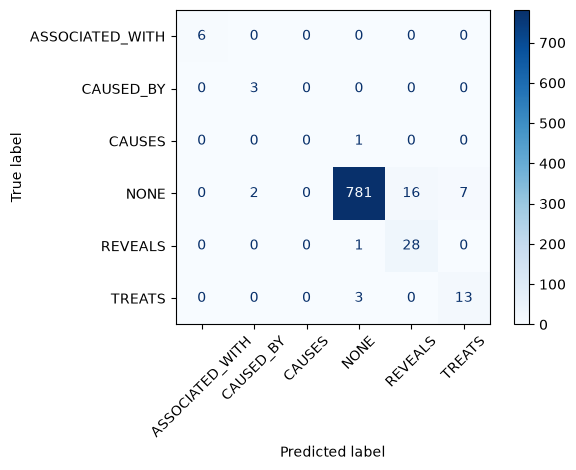

In [15]:
best_row = df_rel.sort_values('macroF1_relações', ascending=False).iloc[0]
print("melhor:", dict(best_row))
best_key = (best_row.modelo, int(best_row.ngram_max))
pred = fitted[best_key].predict(pairs_test)
print(classification_report(pairs_test.rule, pred, zero_division=0, digits=3))
ConfusionMatrixDisplay.from_predictions(pairs_test.rule, pred, xticks_rotation=45, cmap='Blues')
plt.tight_layout(); plt.show()

> **Atenção sobre a avaliação acima.** Os rótulos de teste vêm das mesmas regras que geraram os de treino (avaliação *silver*), e o texto entre as entidades contém o gatilho. Valores altos mostram que o modelo **reproduz** as regras; **não** provam que generaliza. A comparação real entre regras e ML precisa de um conjunto anotado à mão (célula mais adiante).

### Padrões aprendidos (Possibilidade 3 do guia)

Coeficientes da regressão logística sobre n-grams do trecho entre as entidades.

In [16]:
lr_key = ('LogReg', max(2, best_key[1]))
lr_pipe = fitted[lr_key]
names = lr_pipe.named_steps['feat'].get_feature_names_out()
clf = lr_pipe.named_steps['clf']
btw_idx = [i for i, n in enumerate(names) if n.startswith('between__') and not re.search(r'\d', n)]
top = {}
for ci, cls in enumerate(clf.classes_):
    if cls == 'NONE':
        continue
    order = sorted(btw_idx, key=lambda i: -clf.coef_[ci][i])[:8]
    top[cls] = [names[i].replace('between__', '') for i in order]
display(pd.DataFrame(dict([(k, pd.Series(v)) for k, v in top.items()])))

,ASSOCIATED_WITH,CAUSED_BY,REVEALS,TREATS
0,associated with,to,showed,for
1,associated,due,revealed,received
2,accompanied,due to,on,treated
3,accompanied by,secondary,demonstrated,treated with
4,by,secondary to,a,for aspiration
5,with,gastric,scan,patient received
6,along,because,brain,aspiration
7,along with,because of,evidence,responded


In [17]:
# Gatilhos novos: pares que o modelo classifica como relação com confiança alta e as regras NÃO cobrem
proba = lr_pipe.predict_proba(pairs_test)
cls = list(lr_pipe.classes_)
none_i = cls.index('NONE')
pairs_test['ml'] = [cls[i] for i in proba.argmax(1)]
pairs_test['ml_conf'] = proba.max(1)
new = pairs_test[(pairs_test.rule == 'NONE') & (pairs_test.ml != 'NONE') & (pairs_test.ml_conf >= 0.6)]
print(f"{len(new)} pares com relação prevista pelo ML e sem gatilho nas regras")

def ngrams_of(text, nmax=3):
    w = text.split()
    return [' '.join(w[i:i + n]) for n in range(1, nmax + 1) for i in range(len(w) - n + 1)]

c_new, c_all = Counter(), Counter()
for t in pairs_test.between: c_all.update(set(ngrams_of(t)))
for t in new.between: c_new.update(set(ngrams_of(t)))
N_new, N_all = max(len(new), 1), len(pairs_test)
cand = pd.DataFrame([{'ngram': g, 'count_novos': c, 'lift': (c / N_new) / (c_all[g] / N_all)}
                     for g, c in c_new.items() if c >= 5 and not all(x in STOP or not x.isalpha() for x in g.split())])
if len(cand):
    display(cand.sort_values(['lift', 'count_novos'], ascending=False).head(25).round(2))
display(new[['e1', 'between', 'e2', 'ml', 'ml_conf']].sample(min(10, len(new)), random_state=SEED).round(2))

30 pares com relação prevista pelo ML e sem gatilho nas regras


,ngram,count_novos,lift
0,scan,5,8.44


,e1,between,e2,ml,ml_conf
746,MRI,") , confirming the absence of ischemic or",hemorrhagic stroke,REVEALS,0.67
477,computed tomography,"( cect ) scan , identify the",bleeding,REVEALS,0.87
685,MRI,) of the pelvis : the,tumor,REVEALS,0.97
517,CT,scans show the left renal,tumor,REVEALS,0.98
309,ECG,suggested sinus,tachycardia,REVEALS,0.94
360,Surgery,", with the primary complaint of",swelling,TREATS,0.62
840,endocarditis,complicated with rapidly progressive glomerulo...,antibiotic,TREATS,0.84
702,CT,scan did not describe,metastatic disease,REVEALS,0.97
428,FVC,": 66 % predicted ) , along with amelioration of",productive cough,REVEALS,0.67
39,bleeding,was heavy and in clots with associated general...,weakness,ASSOCIATED_WITH,0.84


### Conjunto ouro anotado manualmente

Gera um CSV estratificado (pares com relação por regra, pares novos do ML, pares `NONE`) para anotar `gold_label` com um dos rótulos: `CAUSED_BY, CAUSES, ASSOCIATED_WITH, REVEALS, TREATS, NONE`. Com ~150 pares anotados é possível comparar **regras × ML** de forma honesta.

In [18]:
GOLD_PATH = os.path.join(OUT_DIR, 'gold_relations.csv')
if not os.path.exists(GOLD_PATH):
    parts = [pairs_test[pairs_test.rule != 'NONE'].sample(n=min(50, (pairs_test.rule != 'NONE').sum()), random_state=SEED),
             new.sample(n=min(50, len(new)), random_state=SEED),
             (lambda d: d.sample(n=min(50, len(d)), random_state=SEED))(pairs_test[(pairs_test.rule == 'NONE') & (pairs_test.ml == 'NONE')])]
    g = pd.concat(parts).drop_duplicates(['case_id', 'sentence', 'e1', 'e2'])
    g['gold_label'] = ''
    g[['case_id', 'sentence', 'e1', 't1', 'e2', 't2', 'rule', 'ml', 'ml_conf', 'gold_label']].to_csv(GOLD_PATH, index=False)
    print("arquivo criado:", GOLD_PATH, "-> preencha gold_label e rode esta célula de novo")
else:
    g = pd.read_csv(GOLD_PATH).fillna({'gold_label': ''})
    g = g[g.gold_label != '']
    if len(g) == 0:
        print("preencha a coluna gold_label em", GOLD_PATH)
    else:
        for col in ('rule', 'ml'):
            print(f"--- {col} vs ouro (n={len(g)}) ---")
            print(classification_report(g.gold_label, g[col], zero_division=0, digits=3))

--- rule vs ouro (n=130) ---
                 precision    recall  f1-score   support

ASSOCIATED_WITH      1.000     0.857     0.923         7
      CAUSED_BY      1.000     1.000     1.000         2
         CAUSES      1.000     1.000     1.000         1
           NONE      0.812     0.929     0.867        70
        REVEALS      0.880     0.786     0.830        28
         TREATS      0.875     0.636     0.737        22

       accuracy                          0.846       130
      macro avg      0.928     0.868     0.893       130
   weighted avg      0.852     0.846     0.843       130

--- ml vs ouro (n=130) ---
                 precision    recall  f1-score   support

ASSOCIATED_WITH      1.000     0.857     0.923         7
      CAUSED_BY      0.500     1.000     0.667         2
         CAUSES      0.000     0.000     0.000         1
           NONE      0.870     0.671     0.758        70
        REVEALS      0.614     0.964     0.750        28
         TREATS      0.818  

## 6. Negação de entidades

A Parte 1 criava o nó de sintoma mesmo em *"the patient denied fever"*. Aqui cada menção de entidade é classificada em `AFF` (afirmada) ou `NEG` (negada), no mesmo esquema das relações:

- **Rótulo fraco**: gatilhos no estilo NegEx em uma janela de até 5 tokens antes (`no`, `denied`, `without`, `negative for`...) ou depois da entidade (`was ruled out`, `were negative`...). A janela é cortada em `but`, `however`, `;`, etc. Exames não são negados: em *"X-ray was negative"* o exame foi feito, o que se nega é o achado.
- **Classificador**: TF-IDF de n-grams das janelas esquerda/direita + tipo da entidade, com LogReg / ComplementNB / LinearSVC.

| Texto | Rótulo |
|---|---|
| *the patient **denied** fever* | `NEG` |
| *CT showed **no evidence of** metastatic disease* | `NEG` |
| *pneumonia **was ruled out*** | `NEG` |
| *fever **but no** cough* → fever | `AFF` (o `but` encerra o escopo) |

In [19]:
NEG_PRE  = _re(r"no|not|without|denied|denies|denying|negative for|absence of|free of|ruled out|neither|nor")
NEG_POST = _re(r"(?:was|were|is|are) (?:ruled out|negative|absent|not \w+)")
SCOPE_END = {'but', 'however', 'although', 'though', 'except', ';', '.'}
NEG_WIN = 5

def neg_window(toks, a, b):
    """Janelas esquerda/direita da entidade, cortadas nos terminadores de escopo."""
    left = [t[0].lower() for t in toks[max(0, a - NEG_WIN):a]]
    right = [t[0].lower() for t in toks[b:b + NEG_WIN]]
    cut = [k for k, w in enumerate(left) if w in SCOPE_END]
    if cut: left = left[cut[-1] + 1:]
    cut = [k for k, w in enumerate(right) if w in SCOPE_END]
    if cut: right = right[:cut[0]]
    return ' '.join(left) or 'EMPTY', ' '.join(right) or 'EMPTY'

def make_mentions(sents, spans_key):
    rows = []
    for si, s in enumerate(sents):
        for a, b, t, *_ in s[spans_key]:
            left, right = neg_window(s['tokens'], a, b)
            rows.append({'sent_idx': si, 'case_id': s['case_id'], 'sentence': s['text'], 'span': (a, b),
                         'entity': ' '.join(x[0].lower() for x in s['tokens'][a:b]), 'type': t,
                         'left': left, 'right': right, 'meta': f'T_{t}',
                         'rule': 'NEG' if t != 'Exam' and (NEG_PRE.search(left) or NEG_POST.search(right)) else 'AFF'})
    return pd.DataFrame(rows)

ment_train, ment_test = make_mentions(sents_train, 'gold'), make_mentions(sents_test, 'gold')
print(f"{len(ment_train)} menções de treino | {len(ment_test)} de teste")
display(ment_train.rule.value_counts().to_frame('treino').join(ment_test.rule.value_counts().to_frame('teste')))
display(ment_train[ment_train.rule == 'NEG'][['left', 'entity', 'right', 'type']].sample(8, random_state=SEED))

12747 menções de treino | 3445 de teste


,treino,teste
rule,,
AFF,12132,3292
NEG,615,153


,left,entity,right,type
4787,were no signs for a,metastatic disease,EMPTY,Diagnosis
7303,there was no complication post,surgery,EMPTY,Treatment
9018,there was no,dysphagia,EMPTY,Symptom
12600,she denied,joint pain,and / or a history,Symptom
2274,"no history of trauma ,",surgery,", or childbearing",Treatment
12500,without pressure pain or rebound,pain,EMPTY,Symptom
3594,flank tenderness without hepatomegaly or,splenomegaly,EMPTY,Diagnosis
36,", without having received systemic",chemotherapy,or a second bone marrow,Treatment


In [20]:
def make_neg_pipeline(clf, ngram_max):
    tv = lambda ng: TfidfVectorizer(ngram_range=(1, ng), min_df=2, sublinear_tf=True, token_pattern=r"\S+")
    ct = ColumnTransformer([('left', tv(ngram_max), 'left'),
                            ('right', tv(ngram_max), 'right'),
                            ('meta', TfidfVectorizer(token_pattern=r"\S+", lowercase=False), 'meta')])
    return Pipeline([('feat', ct), ('clf', clf)])

neg_fitted, rows = {}, []
for ng in (1, 2, 3):
    for name, mk in REL_MODELS.items():
        pipe = make_neg_pipeline(mk(), ng).fit(ment_train, ment_train.rule)
        pred = pipe.predict(ment_test)
        neg_fitted[(name, ng)] = pipe
        rows.append({'modelo': name, 'ngram_max': ng,
                     'F1_NEG': f1_score(ment_test.rule, pred, pos_label='NEG', average='binary', zero_division=0)})
df_neg = pd.DataFrame(rows)
display(df_neg.pivot(index='modelo', columns='ngram_max', values='F1_NEG').round(3))

# LogReg com bigramas: usada no grafo porque fornece probabilidade
neg_pipe = neg_fitted[('LogReg', 2)]
print(classification_report(ment_test.rule, neg_pipe.predict(ment_test), zero_division=0, digits=3))

ngram_max,1,2,3
modelo,,,
ComplementNB,0.433,0.605,0.660
LinearSVC,0.971,0.984,0.984
LogReg,0.968,0.981,0.971


              precision    recall  f1-score   support

         AFF      1.000     0.998     0.999      3292
         NEG      0.968     0.993     0.981       153

    accuracy                          0.998      3445
   macro avg      0.984     0.996     0.990      3445
weighted avg      0.998     0.998     0.998      3445



In [21]:
# Padrões aprendidos: n-grams que mais empurram para NEG
names = neg_pipe.named_steps['feat'].get_feature_names_out()
coef = neg_pipe.named_steps['clf'].coef_[0]   # classes_ = ['AFF', 'NEG'] -> coeficiente positivo = NEG
order = np.argsort(-coef)
top_neg = [(names[i].split('__')[0], names[i].split('__')[1], round(coef[i], 2)) for i in order[:15]]
display(pd.DataFrame(top_neg, columns=['janela', 'n-gram', 'peso']))

# Entidades mais negadas no teste (pelas regras)
display(ment_test[ment_test.rule == 'NEG'].groupby(['type', 'entity']).size().sort_values(ascending=False).head(15).to_frame('negações'))

,janela,n-gram,peso
0,left,no,25.56
1,left,without,17.36
2,left,not,16.74
3,left,denied,11.17
4,right,was not,8.75
5,right,not,7.91
6,left,negative for,7.37
7,right,negative,6.42
8,left,free of,6.08
9,left,nor,5.76


negações
type      entity                      
Symptom   pain                      20
Diagnosis tumor                     17
Symptom   fever                     12
          bleeding                  11
Diagnosis hepatitis                  7
Symptom   swelling                   6
Treatment chemotherapy               4
          surgery                    4
Diagnosis metastatic disease         3
Symptom   abdominal pain             3
          edema                      3
          nausea                     3
          vomiting                   3
          chest pain                 3
          cough                      3

In [22]:
# Negações que o modelo encontra e as regras NÃO cobrem
NEG_CONF = 0.6
ment_test['ml_conf'] = neg_pipe.predict_proba(ment_test)[:, list(neg_pipe.classes_).index('NEG')]
ment_test['ml'] = np.where((ment_test.ml_conf >= NEG_CONF) & (ment_test.type != 'Exam'), 'NEG', 'AFF')   # exames não são negados
new_neg = ment_test[(ment_test.rule == 'AFF') & (ment_test.ml == 'NEG')]
print(f"{len(new_neg)} menções negadas pelo ML e não pelas regras")
display(new_neg[['left', 'entity', 'right', 'ml_conf']].head(10).round(2))

def mark_negations(sents, spans_key, model=None):
    """Guarda em s['neg_<spans_key>'] os spans negados (regras se model=None, senão classificador)."""
    for s in sents:
        s['neg_' + spans_key] = set()
    m = make_mentions(sents, spans_key)
    if not len(m):
        return
    if model is None:
        is_neg = (m.rule == 'NEG').values
    else:
        is_neg = (model.predict_proba(m)[:, list(model.classes_).index('NEG')] >= NEG_CONF) & (m.type != 'Exam').values
    for r in m[is_neg].itertuples():
        sents[r.sent_idx]['neg_' + spans_key].add(r.span)

# Conjunto ouro para negação (mesma ideia do de relações)
GOLD_NEG_PATH = os.path.join(OUT_DIR, 'gold_negation.csv')
if not os.path.exists(GOLD_NEG_PATH):
    parts = [ment_test[ment_test.rule == 'NEG'].sample(n=min(40, (ment_test.rule == 'NEG').sum()), random_state=SEED),
             new_neg.sample(n=min(40, len(new_neg)), random_state=SEED),
             ment_test[(ment_test.rule == 'AFF') & (ment_test.ml == 'AFF')].sample(n=40, random_state=SEED)]
    g = pd.concat(parts).drop_duplicates(['case_id', 'sentence', 'entity'])
    g['gold_label'] = ''
    g[['case_id', 'sentence', 'entity', 'type', 'rule', 'ml', 'ml_conf', 'gold_label']].to_csv(GOLD_NEG_PATH, index=False)
    print("arquivo criado:", GOLD_NEG_PATH, "-> preencha gold_label (AFF/NEG) e rode esta célula de novo")
else:
    g = pd.read_csv(GOLD_NEG_PATH).fillna({'gold_label': ''})
    g = g[g.gold_label != '']
    if len(g) == 0:
        print("preencha a coluna gold_label em", GOLD_NEG_PATH)
    else:
        for col in ('rule', 'ml'):
            print(f"--- {col} vs ouro (n={len(g)}) ---")
            print(classification_report(g.gold_label, g[col], zero_division=0, digits=3))

1 menções negadas pelo ML e não pelas regras


,left,entity,right,ml_conf
1214,is often associated with established,atrial fibrillation,or flutter,0.65


--- rule vs ouro (n=81) ---
              precision    recall  f1-score   support

         AFF      0.976     0.889     0.930        45
         NEG      0.875     0.972     0.921        36

    accuracy                          0.926        81
   macro avg      0.925     0.931     0.926        81
weighted avg      0.931     0.926     0.926        81

--- ml vs ouro (n=81) ---
              precision    recall  f1-score   support

         AFF      0.975     0.867     0.918        45
         NEG      0.854     0.972     0.909        36

    accuracy                          0.914        81
   macro avg      0.914     0.919     0.913        81
weighted avg      0.921     0.914     0.914        81



### Relações com filtro de negação

O classificador de relações não sabe o que é negação: em *"CT showed **no** pneumonia"* ele prevê `REVEALS`. Aqui aplicamos o mesmo filtro usado no grafo (par com entidade negada vira `NONE`) e comparamos com o conjunto ouro de relações.

In [23]:
gold_rel = pd.read_csv(GOLD_PATH).fillna({'gold_label': ''})
gold_rel = gold_rel[gold_rel.gold_label != '']
if len(gold_rel) == 0:
    print("preencha a coluna gold_label em", GOLD_PATH)
else:
    keys = ['case_id', 'sentence', 'e1', 'e2']
    ev = pairs_test.drop_duplicates(keys).merge(gold_rel[keys + ['gold_label']], on=keys)

    def drop_negated(labels, key='gold'):
        """Troca o rótulo por NONE quando uma das entidades do par está negada."""
        neg = lambda r: r.span1 in sents_test[r.sent_idx]['neg_' + key] or r.span2 in sents_test[r.sent_idx]['neg_' + key]
        return ['NONE' if neg(r) else l for r, l in zip(ev.itertuples(), labels)]

    mark_negations(sents_test, 'gold')              # negação por regras
    ev['regras+neg'] = drop_negated(ev.rule)
    mark_negations(sents_test, 'gold', neg_pipe)    # negação pelo classificador
    ev['ML+neg'] = drop_negated(ev.ml)

    labels_gold = sorted(set(ev.gold_label) - {'NONE'})
    rows = []
    for name, col in [('regras', 'rule'), ('regras+neg', 'regras+neg'), ('ML', 'ml'), ('ML+neg', 'ML+neg')]:
        f1s = f1_score(ev.gold_label, ev[col], labels=labels_gold, average=None, zero_division=0)
        rows.append({'modelo': name, 'acurácia': (ev.gold_label == ev[col]).mean(),
                     'macroF1_relações': f1s.mean(), **{f'F1_{l}': f for l, f in zip(labels_gold, f1s)}})
    df_rel_gold = pd.DataFrame(rows).set_index('modelo')
    print(f"n = {len(ev)} pares anotados")
    display(df_rel_gold.round(3))

n = 130 pares anotados


,acurácia,macroF1_relações,F1_ASSOCIATED_WITH,F1_CAUSED_BY,F1_CAUSES,F1_REVEALS,F1_TREATS
modelo,,,,,,,
regras,0.846,0.898,0.923,1.000,1.0,0.830,0.737
regras+neg,0.862,0.905,0.923,1.000,1.0,0.863,0.737
ML,0.769,0.632,0.923,0.667,0.0,0.750,0.818
ML+neg,0.823,0.648,0.923,0.667,0.0,0.831,0.818


## 7. Construção do grafo de conhecimento

Duas versões sobre o conjunto de teste:

- **Regras (Parte 1 melhorada)**: entidades do gazetteer completo e relações por gatilho.
- **ML**: entidades do CRF (treinado com os rótulos do gazetteer completo) e relações do classificador (confiança ≥ 0.6).

Entidades negadas viram arestas `NEG_*` (ex.: `NEG_HAS_SYMPTOM`) e não participam de relações entidade–entidade. Nas regras a negação vem dos gatilhos; no ML, do classificador da seção 6.

Nós de entidade são compartilhados entre pacientes (id = `tipo:stems`). Relações entidade–entidade são agregadas com contagem de casos.

In [24]:
# CRF final: treina com o gazetteer completo (rótulos 'gold') e a melhor configuração
lvl, pmi = CONFIGS[best_name]
train_final = [s for s in sents_train if s['gold'] or rng.random() < NEG_KEEP]
crf_final = train_crf(train_final, 'gold', lvl, pmi)
for s, P in zip(sents_test, predict_crf(crf_final, sents_test, lvl, pmi)):
    s['ml'] = P
print("CRF final treinado:", best_name)

CRF final treinado: uni


In [25]:
PATIENT_REL = {'Diagnosis': 'DIAGNOSED_WITH', 'Symptom': 'HAS_SYMPTOM', 'Exam': 'UNDERWENT_EXAM', 'Treatment': 'TREATED_BY'}
UNIT = r"(?:%|mmhg|mm|cm|bpm|[a-zµμ]{1,4}/[a-zµμ0-9]{1,4}(?:\^?\d+)?|x\s*10\^?\d+/?[a-zµμ]*)"
VALUE_RE = re.compile(r"(\d+(?:\.\d+)?)\s*(" + UNIT + r")(?![a-z])", re.I)
REL_CONF = 0.6

def node_key(t, toks):
    return f"{t}:" + ' '.join(stem(x[0]) for x in toks)

def orient(label, t1, t2, n1, n2):
    if label == 'CAUSES':          return n1, n2, 'CAUSES'
    if label == 'CAUSED_BY':       return n2, n1, 'CAUSES'
    if label == 'ASSOCIATED_WITH': return n1, n2, 'ASSOCIATED_WITH'
    if label == 'REVEALS' and (t1 == 'Exam') != (t2 == 'Exam'):
        return (n1, n2, 'REVEALS') if t1 == 'Exam' else (n2, n1, 'REVEALS')
    if label == 'TREATS' and (t1 == 'Treatment') != (t2 == 'Treatment'):
        return (n1, n2, 'TREATS') if t1 == 'Treatment' else (n2, n1, 'TREATS')
    return None

def build_graph(sents, df_cases, spans_key, mode, rel_model=None):
    nodes, edges = {}, defaultdict(lambda: {'count': 0, 'cases': set()})
    for r in df_cases.itertuples():
        nodes[f'P:{r.case_id}'] = {'node_id': f'P:{r.case_id}', 'type': 'Patient', 'label': f'Case {r.case_id}',
                                   'attributes': json.dumps({'age': getattr(r, 'age', None), 'gender': getattr(r, 'gender', None)}, default=str)}
    def add_edge(src, tgt, rel, case):
        e = edges[(src, tgt, rel)]; e['count'] += 1; e['cases'].add(case)

    for s in sents:
        pid = f"P:{s['case_id']}"
        neg = s.get('neg_' + spans_key, set())
        for a, b, t, *_ in s[spans_key]:
            toks = s['tokens'][a:b]; nid = node_key(t, toks)
            nodes.setdefault(nid, {'node_id': nid, 'type': t, 'label': ' '.join(x[0].lower() for x in toks), 'attributes': '{}'})
            add_edge(pid, nid, PATIENT_REL[t] if (a, b) not in neg else 'NEG_' + PATIENT_REL[t], s['case_id'])
            if t == 'Exam':   # resultado numérico logo após o exame, antes da próxima entidade
                nxt = [e[0] for e in s[spans_key] if e[0] >= b]
                stop = s['tokens'][min(nxt)][1] if nxt else len(s['text'])
                m = VALUE_RE.search(s['text'][s['tokens'][b - 1][2]:min(stop, s['tokens'][b - 1][2] + 80)])
                if m:
                    rid = f"R:{s['case_id']}:{nid}:{m.group(1)}{m.group(2).lower()}"
                    nodes.setdefault(rid, {'node_id': rid, 'type': 'ExamResult', 'label': f'{m.group(1)} {m.group(2)}',
                                           'attributes': json.dumps({'value': m.group(1), 'unit': m.group(2)})})
                    add_edge(nid, rid, 'HAS_RESULT', s['case_id'])

    pairs = make_pairs(sents, spans_key)
    if len(pairs):
        if mode == 'rules':
            pairs['label'] = pairs['rule']
        else:
            pr = rel_model.predict_proba(pairs); cl = list(rel_model.classes_)
            pairs['label'] = [cl[i] if p >= REL_CONF else 'NONE' for i, p in zip(pr.argmax(1), pr.max(1))]
        for r in pairs[pairs.label != 'NONE'].itertuples():
            s = sents[r.sent_idx]
            if r.span1 in s.get('neg_' + spans_key, set()) or r.span2 in s.get('neg_' + spans_key, set()):
                continue   # entidade negada não forma relação
            n1 = node_key(r.t1, s['tokens'][r.span1[0]:r.span1[1]]); n2 = node_key(r.t2, s['tokens'][r.span2[0]:r.span2[1]])
            o = orient(r.label, r.t1, r.t2, n1, n2)
            if o and o[0] != o[1]:
                add_edge(*o, r.case_id)
    df_n = pd.DataFrame(nodes.values())
    df_e = pd.DataFrame([{'source': k[0], 'target': k[1], 'relation': k[2], 'count': v['count'], 'n_cases': len(v['cases']), 'cases': ';'.join(sorted(v['cases'])), 'method': mode}
                         for k, v in edges.items()])
    return df_n, df_e

mark_negations(sents_test, 'gold')            # regras: gatilhos
mark_negations(sents_test, 'ml', neg_pipe)    # ML: classificador
nodes_rules, edges_rules = build_graph(sents_test, df_test, 'gold', 'rules')
nodes_ml, edges_ml = build_graph(sents_test, df_test, 'ml', 'ml', rel_model=lr_pipe)
print(f"regras: {len(nodes_rules)} nós, {len(edges_rules)} arestas | ML: {len(nodes_ml)} nós, {len(edges_ml)} arestas")

regras: 853 nós, 2629 arestas | ML: 864 nós, 2646 arestas


In [26]:
import networkx as nx

PAT_REL = set(PATIENT_REL.values()) | {'NEG_' + r for r in PATIENT_REL.values()} | {'HAS_RESULT'}
def graph_stats(n, e):
    ee = e[~e.relation.isin(PAT_REL)]
    G = nx.DiGraph(); G.add_edges_from(zip(e.source, e.target))
    ent = n[~n.type.isin(['Patient', 'ExamResult'])]
    return {'nós de entidade': len(ent), **{f'  {t}': int((ent.type == t).sum()) for t in ENT_TYPES},
            'arestas paciente→entidade': int(e.relation.isin(PATIENT_REL.values()).sum()),
            '  negadas (NEG_*)': int(e.relation.str.startswith('NEG_').sum()),
            'arestas entidade↔entidade': len(ee),
            **{f'  {r}': int((ee.relation == r).sum()) for r in sorted(ee.relation.unique())},
            'grau médio': round(2 * G.number_of_edges() / max(G.number_of_nodes(), 1), 2),
            'densidade': round(nx.density(G), 5),
            'componentes fracamente conexos': nx.number_weakly_connected_components(G)}

st = pd.DataFrame({'regras': graph_stats(nodes_rules, edges_rules), 'ML': graph_stats(nodes_ml, edges_ml)}).fillna(0)
display(st)

def ee_set(e): return set(map(tuple, e[~e.relation.isin(PAT_REL)][['source', 'target', 'relation']].values))
def ent_set(n): return set(n[~n.type.isin(['Patient', 'ExamResult'])].node_id)
A, B = ent_set(nodes_rules), ent_set(nodes_ml); Ea, Eb = ee_set(edges_rules), ee_set(edges_ml)
print(f"Jaccard de nós de entidade: {len(A & B) / len(A | B):.3f} | só ML: {len(B - A)} | só regras: {len(A - B)}")
print(f"Jaccard de arestas entidade↔entidade: {len(Ea & Eb) / max(len(Ea | Eb), 1):.3f} | só ML: {len(Eb - Ea)} | só regras: {len(Ea - Eb)}")

,regras,ML
nós de entidade,246.00000,259.00000
Diagnosis,44.00000,50.00000
Symptom,76.00000,80.00000
Exam,60.00000,58.00000
Treatment,66.00000,71.00000
arestas paciente→entidade,2145.00000,2150.00000
negadas (NEG_*),142.00000,141.00000
arestas entidade↔entidade,38.00000,53.00000
ASSOCIATED_WITH,6.00000,6.00000
CAUSES,4.00000,5.00000


Jaccard de nós de entidade: 0.870 | só ML: 24 | só regras: 11
Jaccard de arestas entidade↔entidade: 0.569 | só ML: 20 | só regras: 5


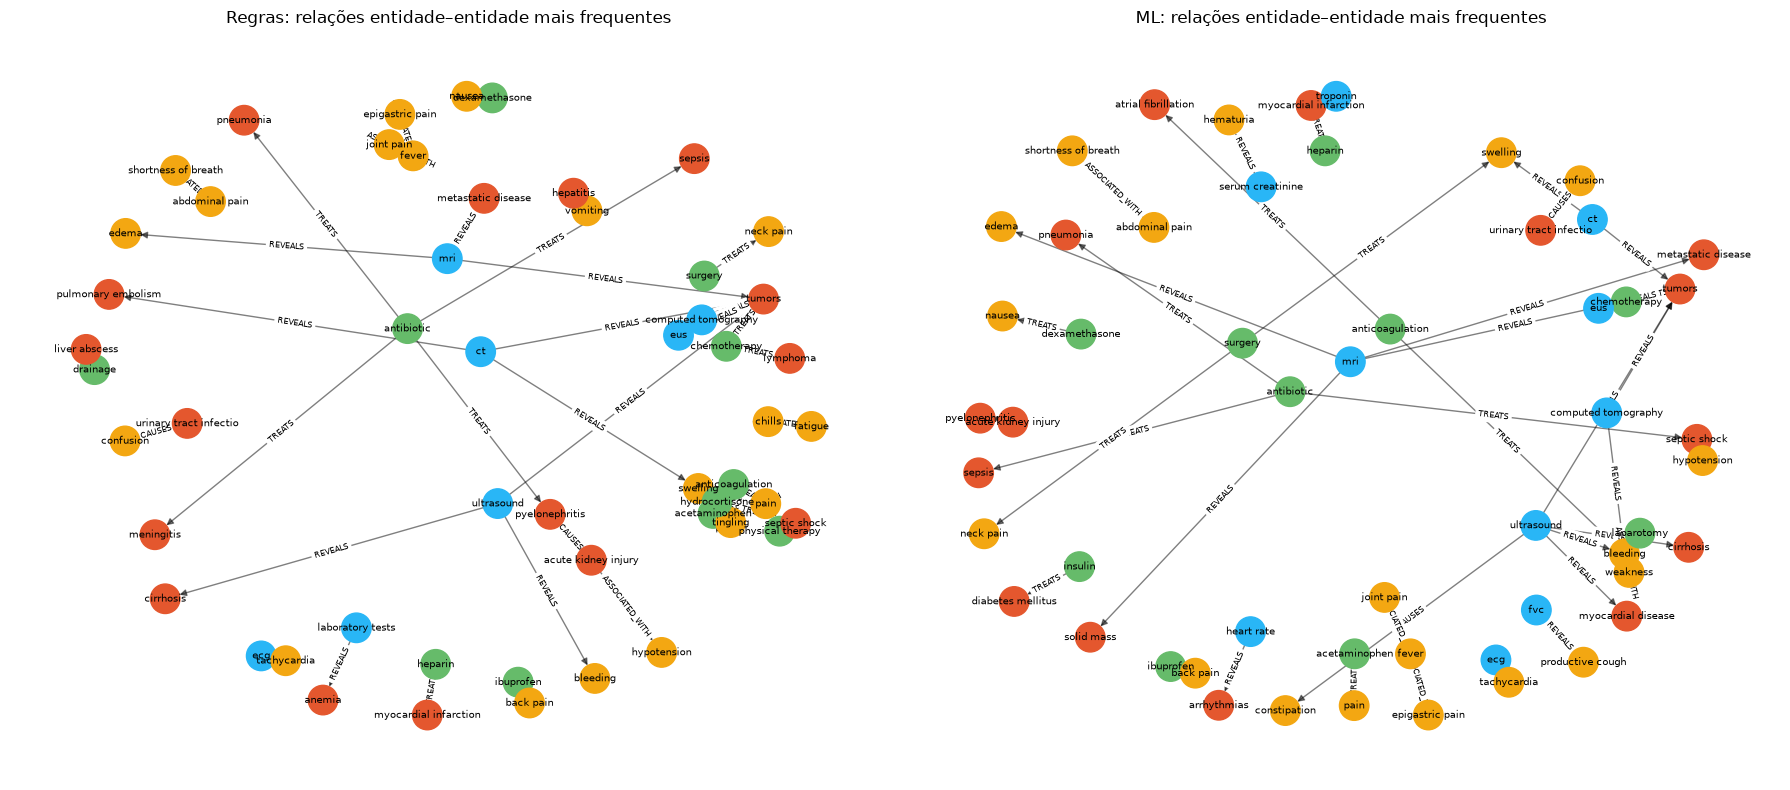

In [27]:
COLORS = {'Patient': '#9aa5b1', 'Diagnosis': '#e4572e', 'Symptom': '#f3a712', 'Exam': '#29b6f6', 'Treatment': '#66bb6a', 'ExamResult': '#ce93d8'}

def draw_graph(n, e, title, case_id=None, top_n=40, ax=None):
    ax = ax or plt.gca()
    if case_id:
        pid = f'P:{case_id}'
        sub = e[(e.source == pid) | (e.target == pid)]
        keep = set(sub.source) | set(sub.target)
        sub = e[e.source.isin(keep) & e.target.isin(keep)]
    else:
        sub = e[~e.relation.isin(PAT_REL)].sort_values('n_cases', ascending=False).head(top_n)
    G = nx.DiGraph()
    meta = n.set_index('node_id')
    for r in sub.itertuples():
        G.add_edge(r.source, r.target, rel=r.relation)
    pos = nx.spring_layout(G, seed=SEED, k=1.2 / max(math.sqrt(max(len(G), 1)), 1))
    nx.draw_networkx_nodes(G, pos, node_color=[COLORS[meta.loc[x, 'type']] for x in G], node_size=450, ax=ax)
    nx.draw_networkx_edges(G, pos, arrows=True, alpha=0.5, ax=ax, node_size=450)
    nx.draw_networkx_labels(G, pos, {x: str(meta.loc[x, 'label'])[:22] for x in G}, font_size=7, ax=ax)
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, 'rel'), font_size=6, ax=ax)
    ax.set_title(title); ax.axis('off')

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
draw_graph(nodes_rules, edges_rules, 'Regras: relações entidade–entidade mais frequentes', ax=axes[0])
draw_graph(nodes_ml, edges_ml, 'ML: relações entidade–entidade mais frequentes', ax=axes[1])
plt.tight_layout(); plt.show()

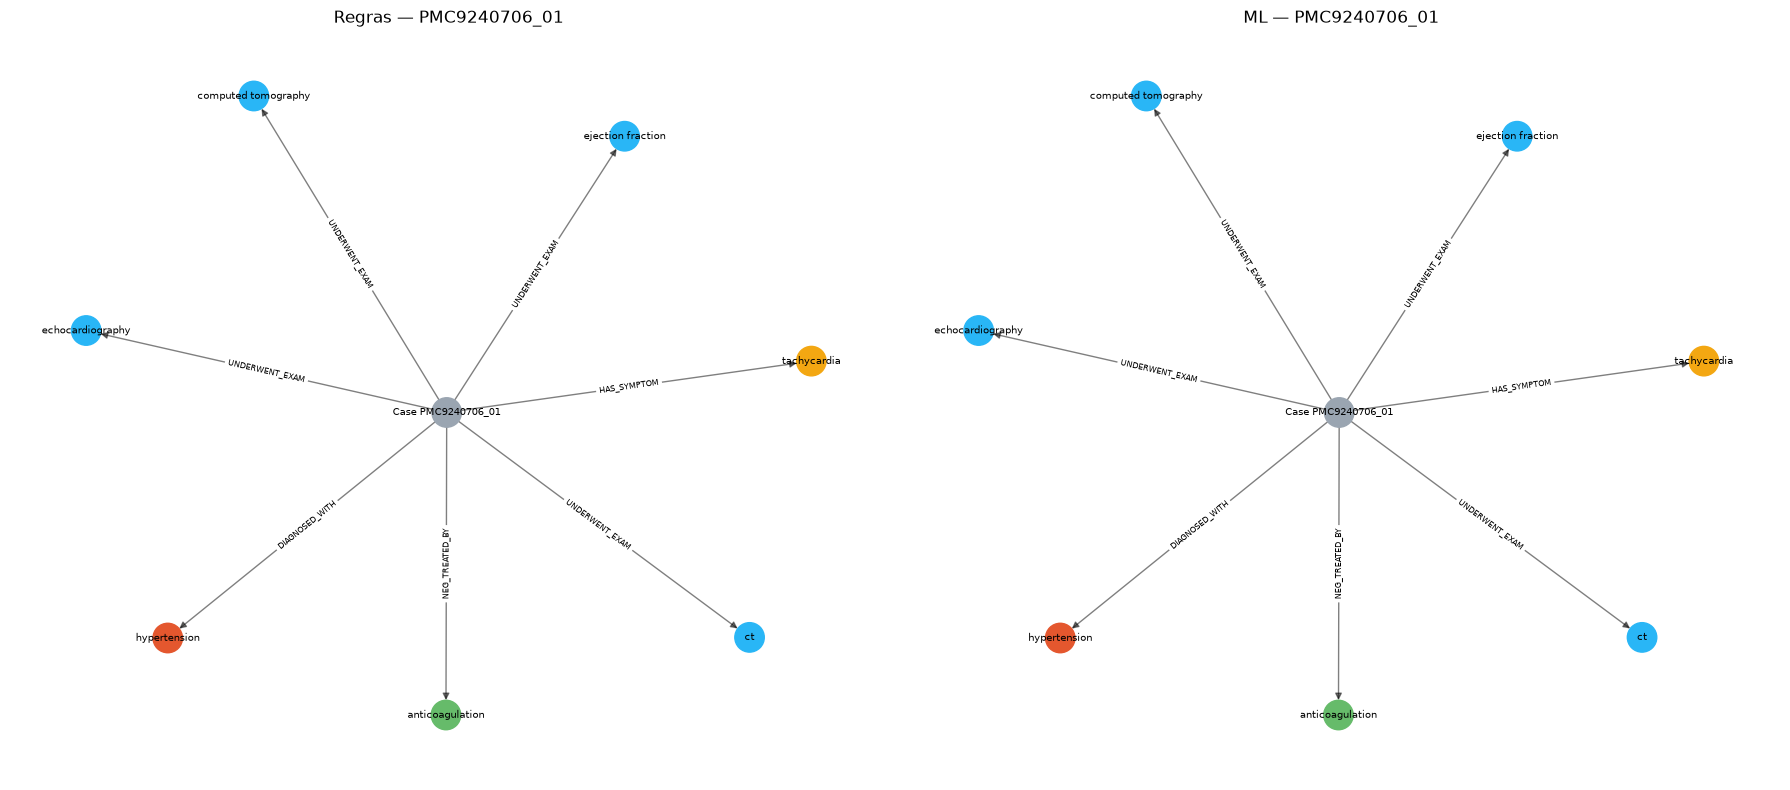

In [28]:
# Subgrafo de um caso, nas duas abordagens
cid = df_test.case_id.iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
draw_graph(nodes_rules, edges_rules, f'Regras — {cid}', case_id=cid, ax=axes[0])
draw_graph(nodes_ml, edges_ml, f'ML — {cid}', case_id=cid, ax=axes[1])
plt.tight_layout(); plt.show()

def to_mermaid(nodes, edges) -> str:
    lines = ["flowchart LR"]
    ids = lambda x: re.sub(r'\W', '_', x)
    for n in nodes.itertuples():
        lines.append(f'  {ids(n.node_id)}["{n.type}<br/>{str(n.label).replace(chr(34), chr(39))}"]')
    for e in edges.itertuples():
        lines.append(f'  {ids(e.source)} -->|{e.relation}| {ids(e.target)}')
    return "\n".join(lines)

In [29]:
# Exportação
nodes_rules.to_csv(f'{OUT_DIR}/nodes_rules.csv', index=False); edges_rules.to_csv(f'{OUT_DIR}/edges_rules.csv', index=False)
nodes_ml.to_csv(f'{OUT_DIR}/nodes_ml.csv', index=False);       edges_ml.to_csv(f'{OUT_DIR}/edges_ml.csv', index=False)
df_ner.round(4).to_csv(f'{OUT_DIR}/results_ner.csv'); df_rel.round(4).to_csv(f'{OUT_DIR}/results_relations.csv', index=False)
df_neg.round(4).to_csv(f'{OUT_DIR}/results_negation.csv', index=False)
if 'df_rel_gold' in globals(): df_rel_gold.round(4).to_csv(f'{OUT_DIR}/results_relations_gold.csv')
df_cand.to_csv(f'{OUT_DIR}/ngram_entity_candidates.csv', index=False)
print("arquivos salvos em", OUT_DIR)

arquivos salvos em ../../data/processed


## 8. Dados para a página de visualização

Gera `src/web/data.js`, lido pela página `src/web/index.html` (demonstração executável): textos dos casos de teste com as entidades marcadas, os dois grafos e as tabelas de resultados.

In [30]:
WEB_DIR = '../../src/web'
os.makedirs(WEB_DIR, exist_ok=True)

def char_spans(s, key):
    """Spans em caracteres: [início, fim, tipo, negada]."""
    neg = s.get('neg_' + key, set())
    return [[s['tokens'][a][1], s['tokens'][b - 1][2], t, int((a, b) in neg)] for a, b, t, *_ in s[key]]

sents_by_case = defaultdict(list)
for s in sents_test:
    sents_by_case[s['case_id']].append({'t': s['text'], 'r': char_spans(s, 'gold'), 'm': char_spans(s, 'ml')})

cases_web = [{'id': r.case_id, 'article': r.article_id, 'title': getattr(r, 'title', ''), 'link': getattr(r, 'link', ''),
              'age': getattr(r, 'age', None), 'gender': getattr(r, 'gender', None), 'sents': sents_by_case[r.case_id]}
             for r in df_test.itertuples() if sents_by_case[r.case_id]]

def records(d):
    return json.loads(d.to_json(orient='records', force_ascii=False))

def graph_web(n, e):
    return {'nodes': n[['node_id', 'type', 'label']].values.tolist(),
            'edges': e[['source', 'target', 'relation', 'n_cases', 'cases']].values.tolist()}

gn = pd.read_csv(GOLD_NEG_PATH).fillna({'gold_label': ''})
gn = gn[gn.gold_label != '']
neg_gold = [{'modelo': name, 'acurácia': (gn.gold_label == gn[col]).mean(),
             'F1_NEG': f1_score(gn.gold_label, gn[col], pos_label='NEG', average='binary', zero_division=0)}
            for name, col in [('regras', 'rule'), ('ML', 'ml')]] if len(gn) else []

base56 = pd.read_csv('../../data/interim/baseline_56casos/results_ner.csv')
top_negated = ment_test[ment_test.rule == 'NEG'].groupby(['type', 'entity']).size().sort_values(ascending=False).head(15)

web = {
    'meta': {'n_cases': len(df), 'n_train': len(df_train), 'n_test': len(df_test),
             'n_sent_train': len(sents_train), 'n_sent_test': len(sents_test), 'hidden_terms': len(HIDDEN)},
    'cases': cases_web,
    'graphs': {'rules': graph_web(nodes_rules, edges_rules), 'ml': graph_web(nodes_ml, edges_ml)},
    'ner': records(df_ner.reset_index()),
    'ner_base56': records(base56),
    'rel_silver': records(df_rel),
    'rel_gold': records(df_rel_gold.reset_index()) if 'df_rel_gold' in globals() else [],
    'neg_silver': records(df_neg),
    'neg_gold': neg_gold,
    'stats': json.loads(st.to_json(force_ascii=False)),
    'jaccard': {'nodes': len(A & B) / len(A | B), 'nodes_only_ml': len(B - A), 'nodes_only_rules': len(A - B),
                'edges': len(Ea & Eb) / max(len(Ea | Eb), 1), 'edges_only_ml': len(Eb - Ea), 'edges_only_rules': len(Ea - Eb)},
    'colloc': records(df_coll.head(40)),
    'cand': records(df_cand.head(40)[['ngram', 'count', 'npmi', 'suggested_type']]),
    'rel_patterns': top,
    'neg_patterns': [[j, g, float(w)] for j, g, w in top_neg],
    'top_negated': [[t, e, int(c)] for (t, e), c in top_negated.items()],
    'novel_entities': [[t, e, c] for (t, e), c in novel.most_common(20)],
}
js = 'window.DATA = ' + json.dumps(web, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, 'item') else str(o)) + ';\n'
with open(f'{WEB_DIR}/data.js', 'w', encoding='utf-8') as f:
    f.write(js)
print(f"{WEB_DIR}/data.js: {len(js) / 1e6:.1f} MB | {len(cases_web)} casos")

../../src/web/data.js: 1.9 MB | 303 casos
